In [2]:
from segment_anything import sam_model_registry, SamPredictor

In [16]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import math

In [4]:
def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)

    img = np.ones((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1], 4))
    img[:,:,3] = 0
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m] = color_mask
    ax.imshow(img)

In [5]:
image = cv2.imread('suitcase.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

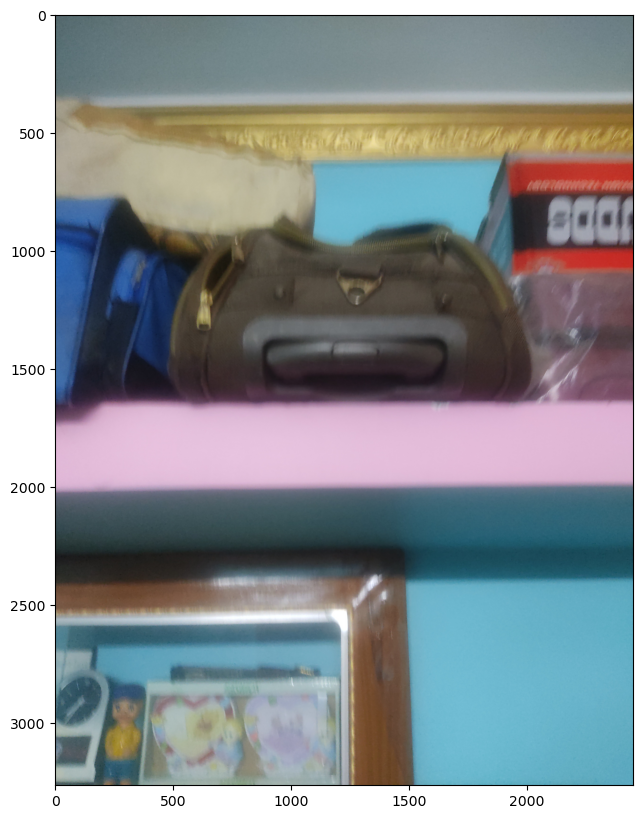

In [6]:
plt.figure(figsize=(10,10))
plt.imshow(image)
plt.axis('on')
plt.show()

In [7]:
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

sam_checkpoint = "SAMVitHModel.pth"
model_type = "vit_h"

device = "cuda"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

mask_generator = SamAutomaticMaskGenerator(sam)

In [8]:
masks = mask_generator.generate(image)

In [10]:
print(len(masks))
print(masks[0].keys())
print("Masks is of type:" ,type(masks))
print("Single entry of masks is of type:" , type(masks[0]))

#print(masks)

58
dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])
Masks is of type: <class 'list'>
Single entry of masks is of type: <class 'dict'>


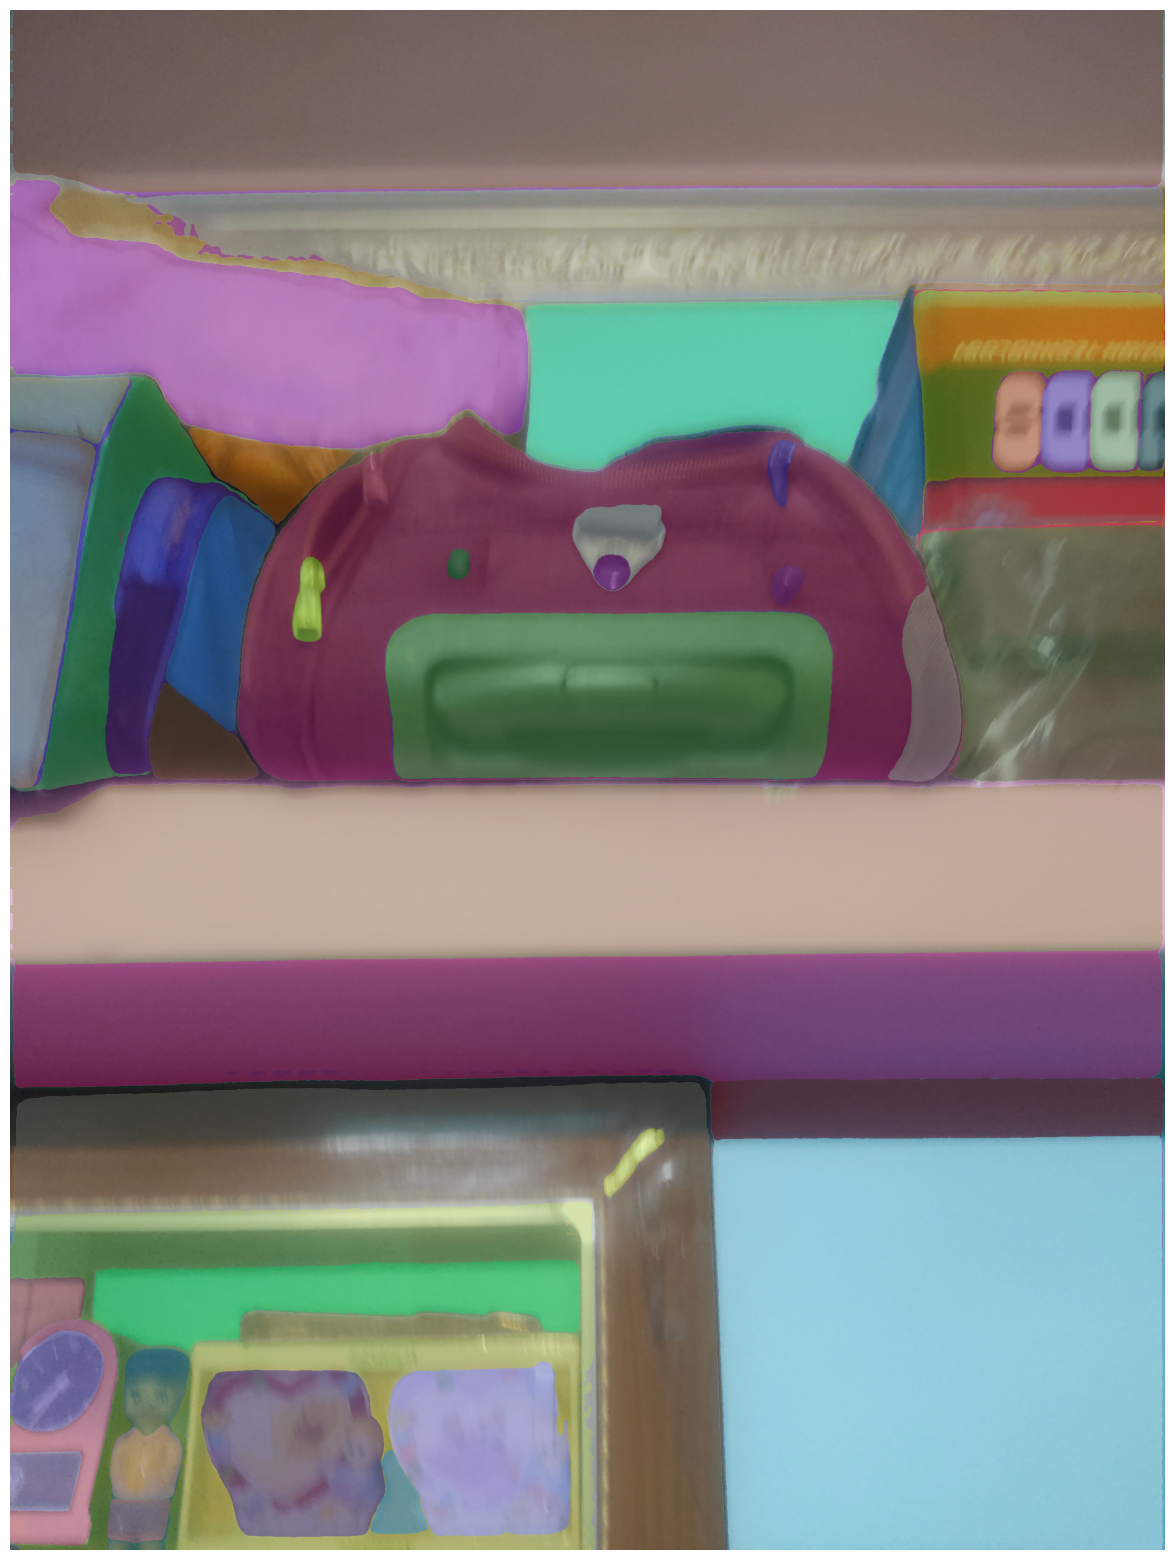

In [11]:
plt.figure(figsize=(20,20))
plt.imshow(image)
show_anns(masks)
plt.axis('off')
plt.show()

In [12]:
def extract_features(mask):
    features = {}
    
    # Area
    features['area'] = np.sum(mask)
    
    # Centroid
    M = cv2.moments(mask.astype(np.uint8))
    features['centroid'] = (M['m10'] / M['m00'], M['m01'] / M['m00']) if M['m00'] != 0 else (0, 0)
    
    # Bounding Box
    y, x = np.where(mask)
    features['bounding_box'] = [min(x), min(y), max(x), max(y)]  # minX, minY, maxX, maxY
    
    # Aspect Ratio
    bbox_width = max(x) - min(x)
    bbox_height = max(y) - min(y)
    features['aspect_ratio'] = bbox_width / bbox_height if bbox_height > 0 else 0
    
    return features['bounding_box']

In [13]:
bbox_list = []
for i in range(len(masks)):
    mask_data = masks[i]['segmentation']
    bbox_list.append(extract_features(mask_data))
    # Now, 'features' holds the extracted features for the ith mask
    # You can now use 'features' for further analysis or feed it into a classifier


In [14]:
def crop_feature(image, bbox):
    # Ensure bbox coordinates are within image bounds
    x_min, y_min, x_max, y_max = bbox
    x_min, y_min = max(0, x_min), max(0, y_min)
    x_max, y_max = min(image.shape[1]-1, x_max), min(image.shape[0]-1, y_max)

    if x_max <= x_min or y_max <= y_min:
        return None  # Return None if the bounding box is invalid

    # Crop the image using the bounding box coordinates
    crop = image[y_min:y_max, x_min:x_max]
    return crop

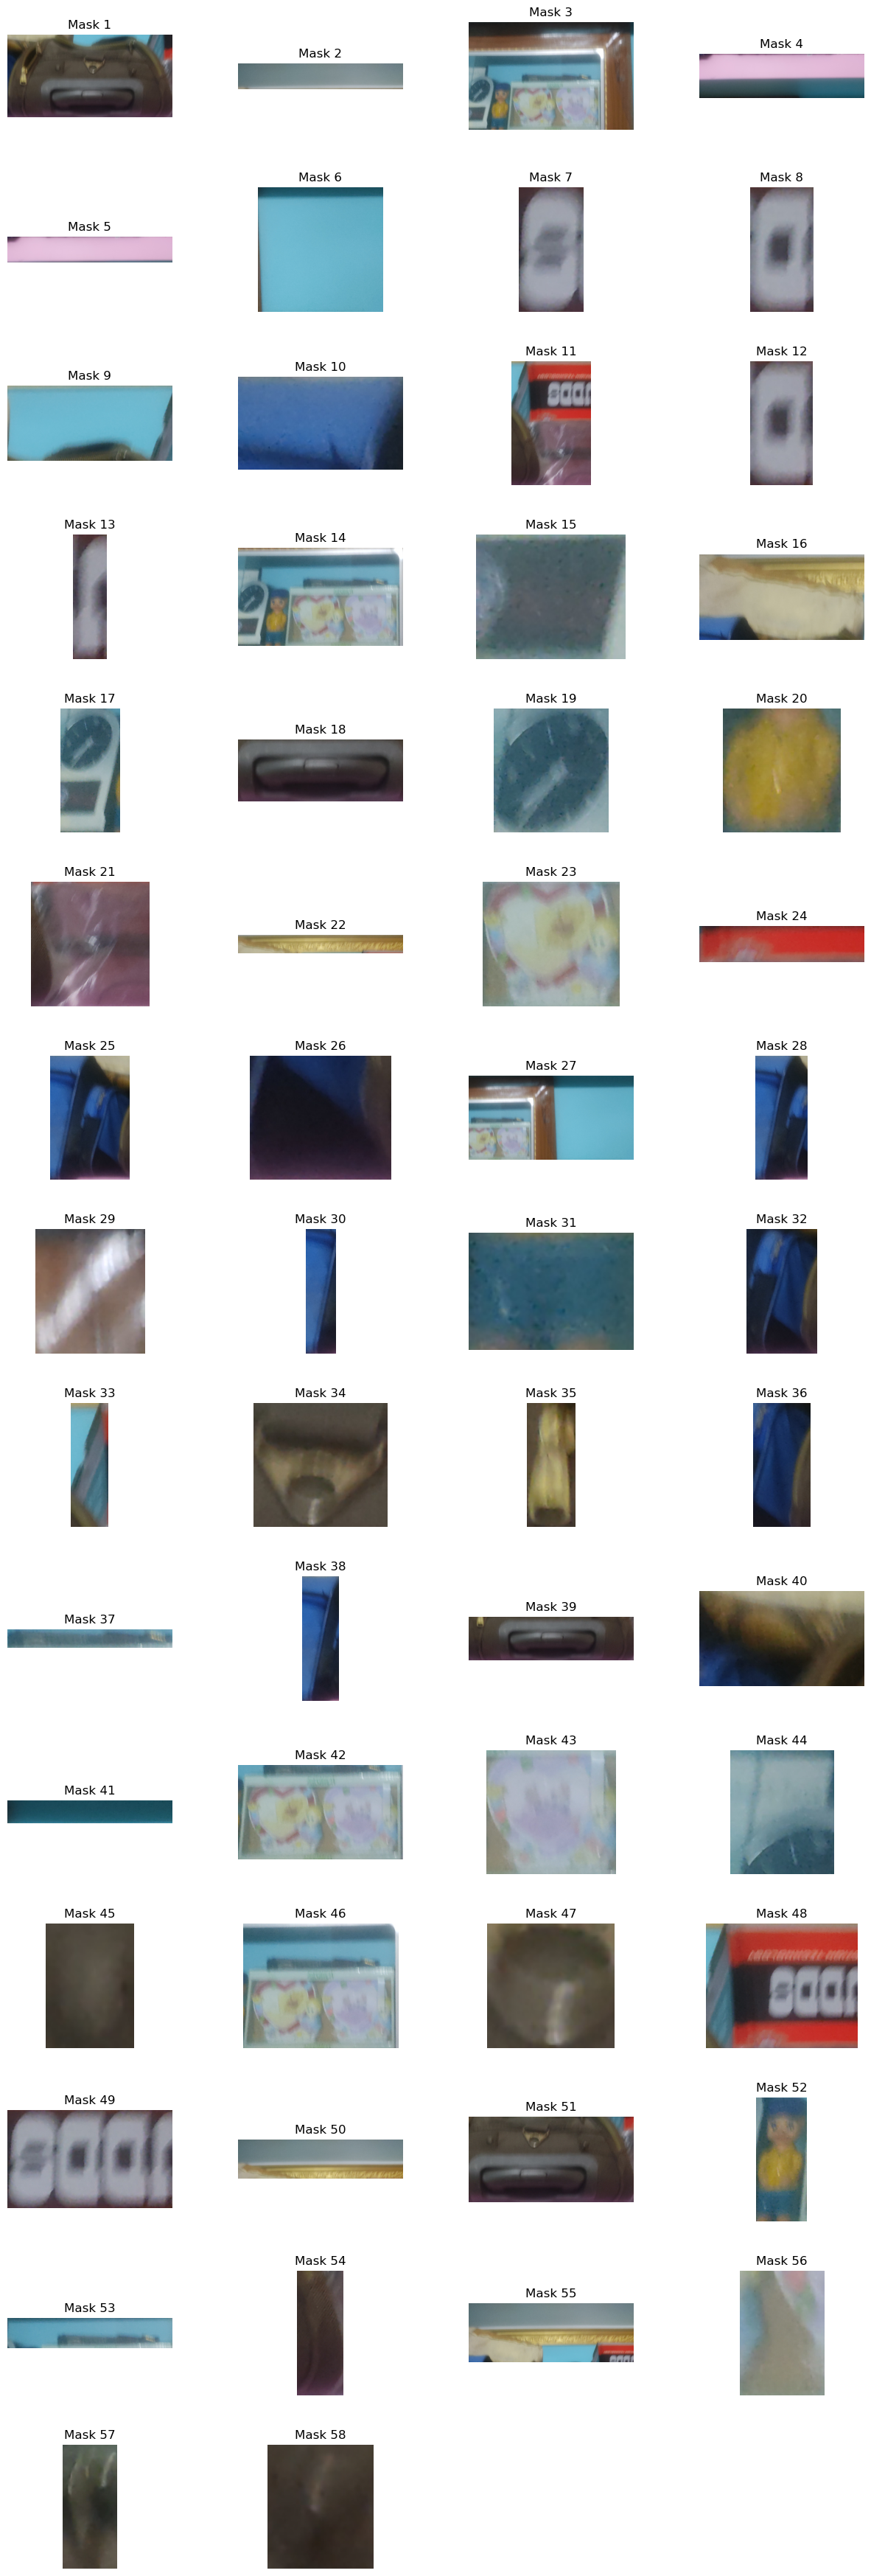

In [17]:
# Determine the size of the grid
num_masks = len(masks)
num_columns = 4  # You can adjust this
num_rows = math.ceil(num_masks / num_columns)

# Set up the matplotlib figure and axes
fig, axs = plt.subplots(num_rows, num_columns, figsize=(15, num_rows * 3))
fig.subplots_adjust(hspace=0.4, wspace=0.4)

# Flatten the array of axes for easy indexing
axs = axs.flatten()

# Loop over the masks and draw the cropped bounding box for each mask
valid_crops = 0
for idx, bbox in enumerate(bbox_list):
    try:
        cropped_image = crop_feature(image, bbox)
        if cropped_image is not None:
            axs[valid_crops].imshow(cropped_image)
            axs[valid_crops].axis('off')  # Hide the axis
            axs[valid_crops].set_title(f"Mask {idx + 1}")
            valid_crops += 1
    except Exception as e:
        # If an error occurred during cropping, skip this mask and continue
        print(f"Skipping mask {idx + 1} due to error: {e}")

# If there are any remaining empty subplots, turn off their axes.
for ax in axs[valid_crops:]:
    ax.axis('off')

# Show the plot
plt.show()